<a href="https://colab.research.google.com/github/martalombardi/rhetorical_signatures/blob/main/nyt_news.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NYT News Articles

In [31]:
from pathlib import Path
import runpy

ROOT = Path("/content/rhetorical_signatures")
_INITIALIZER = ROOT / "code" / "initialize_experiment.py"
if not _INITIALIZER.is_file():
    raise FileNotFoundError(f"Missing initializer: {_INITIALIZER}")

# run_path returns the variables defined by the initialization script;
# publish them to notebook globals for compatibility with cells 02 onward.
globals().update(runpy.run_path(str(_INITIALIZER)))


Environment ready
-------------------------------------------------------
Python: 3.13.16
PyTorch: 2.14.1+cu130
CUDA available: True
spaCy: 3.8.18

Dataset selection
-------------------------------------------------------
Selection algorithm version: 2
Sampling: proportional
Sentence range: 10–10
Number of bins: 10
Seed: 42
Include Human: True

RST parsing
-------------------------------------------------------
Number of sentences: 10
Matched: False
Model: tchewik/isanlp_rst_v3
Model version: rstdt
Device: auto
Document limit: None
Retry errors: False

XML forests
-------------------------------------------------------
Grouping variables: ['genre', 'source', 'n_sentences']
Rebuild: False
Validate: True
External metadata: None

TreeRePair compression
-------------------------------------------------------
Genre: news
Sentences: 10
Sources: None
Rebuild: False
Textual grammar: True
Optimization: filesize
Max rank: None
Timeout: 600s

TreeDePair validation
-------------------------------

In [32]:
# ------------------------------------------------------------
# RAID dataset availability
# ------------------------------------------------------------

raid_downloader = load_project_module(
    "raid_downloader",
    PROCESSING_DIR / "01_download_raid.py",
)

raid_downloader.download_raid()

RAID dataset already available: /content/rhetorical_signatures/data/raw/raid/train.csv


PosixPath('/content/rhetorical_signatures/data/raw/raid/train.csv')

In [33]:
documents, sentences = process_sentences.load_or_analyze_sentence_lengths(
    domain=DOMAIN,
    prompting=PROMPTING,
    attack=ATTACK,
    decoding=DECODING,
    repetition_penalty=REPETITION_PENALTY,
    rebuild=SENTENCE_ANALYSIS_REBUILD,
    show_progress=SENTENCE_ANALYSIS_SHOW_PROGRESS,
)

sentence_stats = sentences.merge(
    documents[["id", "source"]],
    on="id",
    how="left",
    validate="many_to_one",
)

assert sentence_stats["source"].notna().all()

print(
    f"{len(documents):,} documents | "
    f"{len(sentences):,} sentences | "
    f"{documents['source'].nunique()} sources"
)

Loaded existing sentence analysis: /content/rhetorical_signatures/results/sentences_report/domain-news__prompting-all__attack-null__decoding-greedy__rep-no
12,460 documents | 188,459 sentences | 7 sources


In [34]:
source_order = [
    source for source in MODEL_ORDER
    if source in documents["source"].unique()
]

document_summary = (
    documents.groupby("source")
    .agg(
        documents=("id", "size"),
        median_sentences=("n_sentences", "median"),
        mean_sentences=("n_sentences", "mean"),
        median_words=("n_words", "median"),
        mean_words=("n_words", "mean"),
    )
    .reindex(source_order)
)

sentence_summary = (
    sentence_stats.groupby("source")
    .agg(
        sentences=("id", "size"),
        median_words_per_sentence=("n_words", "median"),
        mean_words_per_sentence=("n_words", "mean"),
    )
    .reindex(source_order)
)

descriptive_summary = document_summary.join(sentence_summary)

display(
    descriptive_summary.style.format({
        "documents": "{:,.0f}",
        "sentences": "{:,.0f}",
        "median_sentences": "{:.1f}",
        "mean_sentences": "{:.1f}",
        "median_words": "{:.1f}",
        "mean_words": "{:.1f}",
        "median_words_per_sentence": "{:.1f}",
        "mean_words_per_sentence": "{:.1f}",
    })
)

,documents,median_sentences,mean_sentences,median_words,mean_words,sentences,median_words_per_sentence,mean_words_per_sentence
source,,,,,,,,
Human,"1,780",16.0,18.1,329.0,370.7,"32,226",20.0,20.5
ChatGPT,"1,780",17.0,16.5,362.0,348.4,"29,353",21.0,21.1
GPT-4,"1,780",17.0,17.6,354.0,353.1,"31,300",20.0,20.1
Mistral 7B,"1,780",18.0,18.2,322.0,318.3,"32,375",16.0,17.5
Mistral 7B (Chat),"1,780",11.0,11.0,246.0,247.4,"19,646",22.0,22.5
Cohere,"1,780",14.0,13.9,302.0,294.1,"24,811",21.0,21.1
Cohere (Chat),"1,780",9.0,10.5,207.0,226.7,"18,748",21.0,21.5


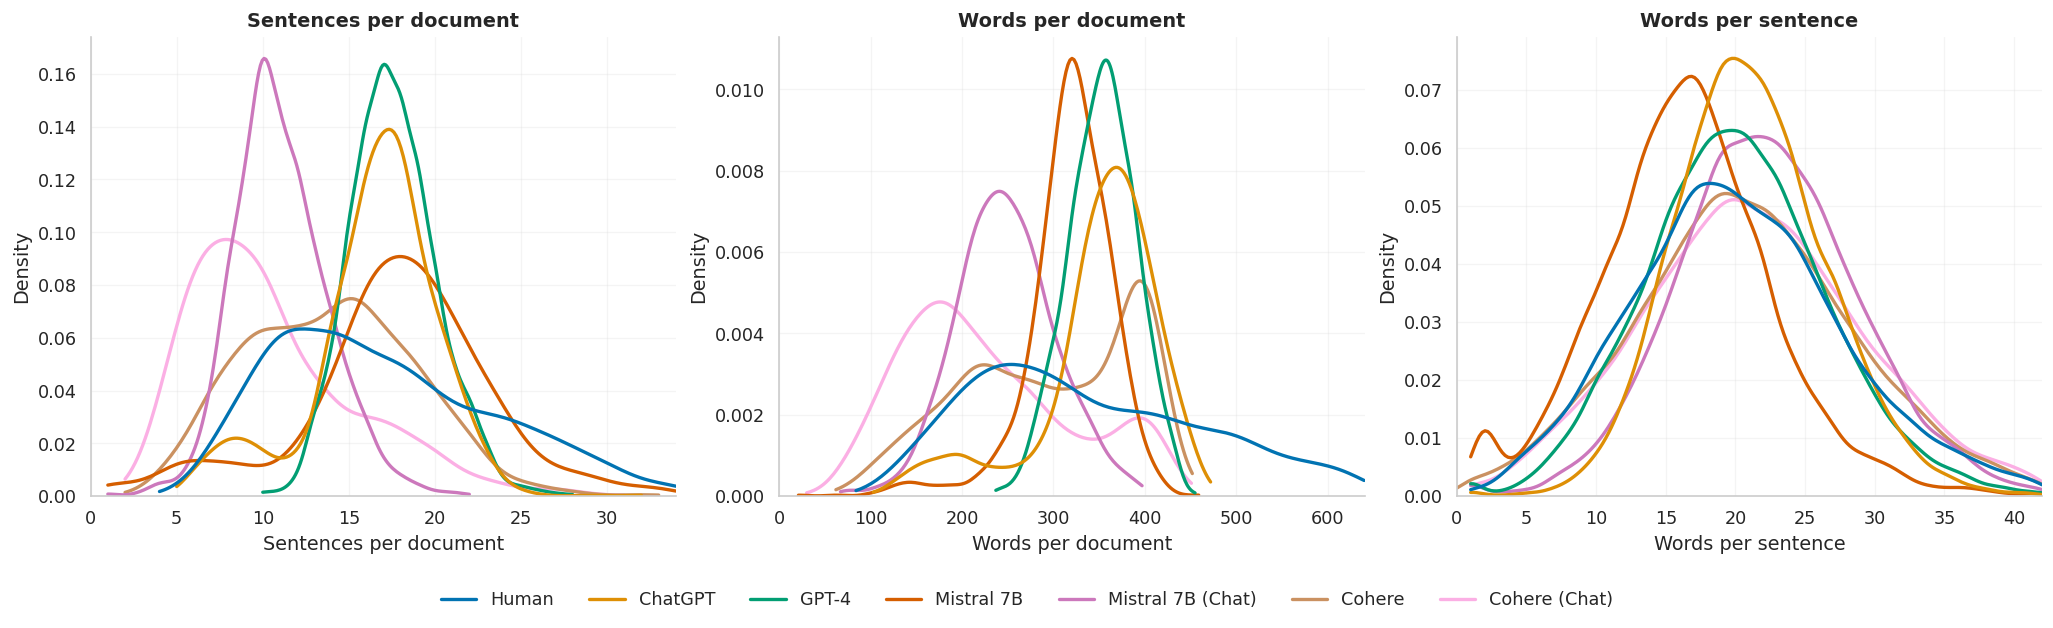

In [35]:

fig, axes = plt.subplots(
    1, 3, figsize=(17, 4.6), constrained_layout=True
)

variables = [
    (documents, "n_sentences", "Sentences per document"),
    (documents, "n_words", "Words per document"),
    (sentence_stats, "n_words", "Words per sentence"),
]

palette = dict(zip(
    source_order,
    sns.color_palette("colorblind", n_colors=len(source_order))
))

for ax, (data, column, xlabel) in zip(axes, variables):
    upper = data[column].quantile(0.99)

    subset = data.loc[
        data[column].notna() & data[column].le(upper)
    ].copy()

    sns.kdeplot(
        data=subset,
        x=column,
        hue="source",
        hue_order=source_order,
        palette=palette,
        common_norm=False,
        bw_adjust=1.0,
        cut=0,
        clip=(0, None),
        linewidth=2,
        fill=False,
        warn_singular=False,
        ax=ax,
        legend=False,
    )

    ax.set(
        xlabel=xlabel,
        ylabel="Density",
        title=xlabel,
    )
    ax.set_xlim(left=0, right=upper)
    ax.grid(alpha=0.2)

from matplotlib.lines import Line2D

handles = [
    Line2D(
        [0], [0],
        color=palette[source],
        lw=2,
        label=source,
    )
    for source in source_order
]

fig.legend(
    handles=handles,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=min(len(source_order), 7),
)

plt.show()

Loaded selection: /content/rhetorical_signatures/data/filtered/sentences/domain-news__prompting-all__attack-null__decoding-greedy__rep-no/range-10-10__best-10__matched-1__proportional__seed-42__bins-10__human-1
Loaded selection: /content/rhetorical_signatures/data/filtered/sentences/domain-news__prompting-all__attack-null__decoding-greedy__rep-no/range-10-10__best-10__matched-0__proportional__seed-42__bins-10__human-1
Matched: n=10, 445 documents per source
Unmatched: n=10, 884 documents per source


,selection,source,best_n,eligible,selected
0,Matched,Human,10,1608,445
1,Matched,ChatGPT,10,1645,445
2,Matched,GPT-4,10,1780,445
3,Matched,Mistral 7B,10,1617,445
4,Matched,Mistral 7B (Chat),10,1281,445
5,Matched,Cohere,10,1406,445
6,Matched,Cohere (Chat),10,884,445
7,Unmatched,Human,10,1608,884
8,Unmatched,ChatGPT,10,1645,884
9,Unmatched,GPT-4,10,1780,884


,selection,source,median_before,median_after,wasserstein
0,Matched,Human,205.0,205.0,1.11
1,Matched,ChatGPT,209.0,208.0,1.37
2,Matched,GPT-4,206.0,206.0,1.14
3,Matched,Mistral 7B,178.0,177.0,1.61
4,Matched,Mistral 7B (Chat),219.0,219.0,0.84
5,Matched,Cohere,212.0,211.0,1.26
6,Matched,Cohere (Chat),214.0,214.0,1.37
7,Unmatched,Human,205.0,205.0,0.58
8,Unmatched,ChatGPT,209.0,209.0,0.28
9,Unmatched,GPT-4,206.0,206.0,0.38


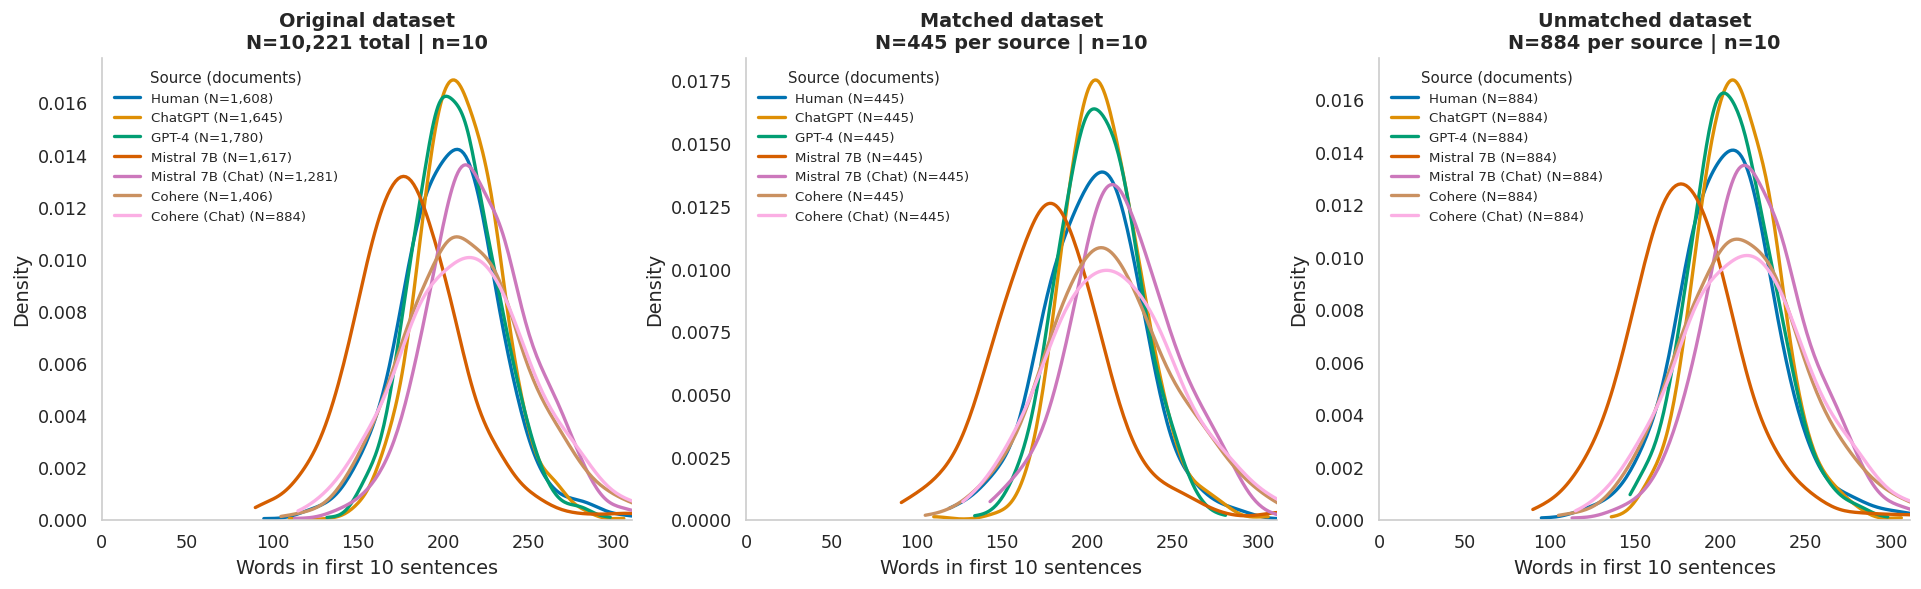

In [36]:
# Selection and diagnostics — no helper definitions in the notebook
selection_kwargs = dict(
    documents=documents, sentences=sentences,
    min_sentences=MIN_SENTENCES, max_sentences=MAX_SENTENCES,
    domain=DOMAIN, prompting=PROMPTING, attack=ATTACK,
    decoding=DECODING, repetition_penalty=REPETITION_PENALTY,
    sampling=SAMPLING, n_bins=N_BINS, seed=SEED,
    include_human=INCLUDE_HUMAN,
)

selected_matched, comparison_matched = (
    process_sentences.load_or_select_sentence_dataset(
        **selection_kwargs, match_source_id=True
    )
)
selected_unmatched, comparison_unmatched = (
    process_sentences.load_or_select_sentence_dataset(
        **selection_kwargs, match_source_id=False
    )
)

count_summary, distribution_check = process_sentences.selection_diagnostics(
    documents, sentences,
    {
        'Matched': (selected_matched, comparison_matched),
        'Unmatched': (selected_unmatched, comparison_unmatched),
    },
)


### Parsing

In [38]:

# ============================================================
# 02 — Load existing RST trees (no additional parsing)
# ============================================================

import json

# Locate the existing RST dataset
run_dir = (
    RST_DATA_DIR
    / "unmatched"
    / "domain-news__prompting-all__attack-null__decoding-greedy__rep-no"
)

selection_dirs = sorted(run_dir.glob("range-10-10__best-10__*"))

if len(selection_dirs) != 1:
    raise RuntimeError(
        f"Expected one RST dataset, found {len(selection_dirs)}"
    )

output = selection_dirs[0]
trees_file = output / "trees.jsonl"

if not trees_file.is_file():
    raise FileNotFoundError(trees_file)

# Load only the trees already available
with trees_file.open("r", encoding="utf-8") as f:
    trees = [json.loads(line) for line in f if line.strip()]

print(f"RST trees loaded: {len(trees)}")
print(f"Output: {output}")
print("No additional RST parsing performed.")

RST trees loaded: 4409
Output: /content/rhetorical_signatures/data/rst/unmatched/domain-news__prompting-all__attack-null__decoding-greedy__rep-no/range-10-10__best-10__matched-0__proportional__seed-42__bins-10__human-1
No additional RST parsing performed.


### Build forests

In [39]:
# ============================================================
# 03 — Load or build grouped XML forests (max 500 per source)
# ============================================================

import json
from collections import Counter

MAX_TREES_PER_SOURCE = 200

trees_file = Path(output) / "trees.jsonl"
limited_trees_file = Path(output) / "trees_first500_per_source.jsonl"

counts = Counter()

with trees_file.open("r", encoding="utf-8") as src, \
     limited_trees_file.open("w", encoding="utf-8") as dst:

    for line in src:
        if not line.strip():
            continue

        record = json.loads(line)

        # Assumes each RST record contains the source field.
        source = record["source"]

        if counts[source] >= MAX_TREES_PER_SOURCE:
            continue

        dst.write(line)
        counts[source] += 1

print("Selected RST trees per source:")
for source, count in sorted(counts.items()):
    print(f"  {source}: {count}")

(
    forests_dir,
    forest_paths,
    forest_index,
    manifest,
) = forest_builder.load_or_build_forests(
    trees_file=limited_trees_file,
    metadata_file=FOREST_METADATA_FILE,
    group_by=FOREST_GROUP_BY,
    rebuild=True,
    validate=FOREST_VALIDATE,
)

Selected RST trees per source:
  ChatGPT: 200
  Cohere: 200
  Cohere (Chat): 200
  GPT-4: 200
  Human: 200
Rebuilding XML forests...
[1/5] 0001__genre-news__source-ChatGPT__n_sentences-10.xml: 200 trees
[2/5] 0002__genre-news__source-Cohere__n_sentences-10.xml: 200 trees
[3/5] 0003__genre-news__source-Cohere_Chat__n_sentences-10.xml: 200 trees
[4/5] 0004__genre-news__source-GPT-4__n_sentences-10.xml: 200 trees
[5/5] 0005__genre-news__source-Human__n_sentences-10.xml: 200 trees

FOREST GENERATION COMPLETE
RST trees: 1000
XML forests: 5
Output: /content/rhetorical_signatures/data/rst/unmatched/domain-news__prompting-all__attack-null__decoding-greedy__rep-no/range-10-10__best-10__matched-0__proportional__seed-42__bins-10__human-1/forests

XML FORESTS READY
Forests: 5
RST trees: 1000
Directory: /content/rhetorical_signatures/data/rst/unmatched/domain-news__prompting-all__attack-null__decoding-greedy__rep-no/range-10-10__best-10__matched-0__proportional__seed-42__bins-10__human-1/forests


# TreeRePair

In [40]:
# ============================================================
# 04 — TreeRePair grammar compression (500 trees per source)
# ============================================================

compression_dir, compression_results, compression_manifest = (
    tree_compressor.run_treerepair(
        forests_dir=forests_dir,
        binary=TREEREPAIR_BINARY,
        genre=COMPRESSION_GENRE,
        n_sentences=COMPRESSION_N_SENTENCES,
        sources=COMPRESSION_SOURCES,
        rebuild=True,
        textual=COMPRESSION_TEXTUAL,
        optimize=COMPRESSION_OPTIMIZE,
        max_rank=COMPRESSION_MAX_RANK,
        timeout=COMPRESSION_TIMEOUT,
        continue_on_error=COMPRESSION_CONTINUE_ON_ERROR,
    )
)

compression_summary = pd.DataFrame(compression_results)

display(compression_summary)

[1/5] ChatGPT
  COMPLETED_UNVALIDATED (returncode=0)
[2/5] Cohere
  COMPLETED_UNVALIDATED (returncode=0)
[3/5] Cohere_Chat
  COMPLETED_UNVALIDATED (returncode=0)
[4/5] GPT-4
  COMPLETED_UNVALIDATED (returncode=0)
[5/5] Human
  COMPLETED_UNVALIDATED (returncode=0)


,source,forest,status,returncode,cached,rep_file,reptxt_file,rep_bytes,reptxt_bytes,forest_sha256
0,ChatGPT,/content/rhetorical_signatures/data/rst/unmatc...,COMPLETED_UNVALIDATED,0,False,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,5491,24992,2000a230bd8a96d83c94c2c86725eae02678862adb9bb9...
1,Cohere,/content/rhetorical_signatures/data/rst/unmatc...,COMPLETED_UNVALIDATED,0,False,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,6502,29433,03ff384d28aca199a0464eb8e9bf0e404bc62a0fd9e1ae...
2,Cohere_Chat,/content/rhetorical_signatures/data/rst/unmatc...,COMPLETED_UNVALIDATED,0,False,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,6199,27603,f3e886a8eaeb6b9f19f8e6c4c0f58c2f1d90f872dbd229...
3,GPT-4,/content/rhetorical_signatures/data/rst/unmatc...,COMPLETED_UNVALIDATED,0,False,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,5593,25423,a893f3dafe7b2874a3bfb617cd6332346989e4baac3bc2...
4,Human,/content/rhetorical_signatures/data/rst/unmatc...,COMPLETED_UNVALIDATED,0,False,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,6356,28495,18a101083acfa89267c788bbb10e93c8244332d6d0a77c...


In [41]:

# ============================================================
# 05 — TreeRePair grammar validation
# ============================================================

validation_dir, validation_results, validation_manifest = (
    grammar_validator.validate_grammars(
        forests_dir=forests_dir,
        compression_dir=compression_dir,
        binary=TREEDEPAIR_BINARY,
        genre=COMPRESSION_GENRE,
        n_sentences=COMPRESSION_N_SENTENCES,
        sources=COMPRESSION_SOURCES,
        rebuild=VALIDATION_REBUILD,
        timeout=VALIDATION_TIMEOUT,
        keep_reconstructed=VALIDATION_KEEP_RECONSTRUCTED,
    )
)

validation_summary = pd.DataFrame(validation_results)

display(validation_summary)


[1/5] ChatGPT
  VALIDATED (cached)
[2/5] Cohere
  VALIDATED (cached)
[3/5] Cohere_Chat
  VALIDATED (cached)
[4/5] GPT-4
  VALIDATED (cached)
[5/5] Human
  VALIDATED (cached)


,source,forest,rep_file,restored_file,cached,returncode,original_trees,reconstructed_trees,document_ids_match,structure_match,original_root,reconstructed_root,validated,status
0,ChatGPT,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,True,0,200,200,True,True,forest,forest,True,VALIDATED
1,Cohere,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,True,0,200,200,True,True,forest,forest,True,VALIDATED
2,Cohere_Chat,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,True,0,200,200,True,True,forest,forest,True,VALIDATED
3,GPT-4,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,True,0,200,200,True,True,forest,forest,True,VALIDATED
4,Human,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,/content/rhetorical_signatures/data/rst/unmatc...,True,0,200,200,True,True,forest,forest,True,VALIDATED


### Extract Motifs

In [42]:
# CELL 06 — Extract RST motifs

motifs_dir, motif_results, motif_manifest = (
    motif_extractor.extract_motifs(
        forests_dir=forests_dir,
        compression_dir=compression_dir,
        results_dir=RESULTS_DIR,
        genre=COMPRESSION_GENRE,
        n_sentences=COMPRESSION_N_SENTENCES,
        sources=COMPRESSION_SOURCES,
        rebuild=MOTIF_REBUILD,
        min_relations=MOTIF_MIN_RELATIONS,
        min_depth=MOTIF_MIN_DEPTH,
        include_wildcards=MOTIF_INCLUDE_WILDCARDS,
        continue_on_error=MOTIF_CONTINUE_ON_ERROR,
    )
)

display(pd.DataFrame(motif_results))

print(f"\nMotifs saved to: {motifs_dir}")

[1/5] genre-news__n_sentences-10 / ChatGPT
  Cached: 82 motifs
[2/5] genre-news__n_sentences-10 / Cohere
  Cached: 78 motifs
[3/5] genre-news__n_sentences-10 / Cohere_Chat
  Cached: 44 motifs
[4/5] genre-news__n_sentences-10 / GPT-4
  Cached: 33 motifs
[5/5] genre-news__n_sentences-10 / Human
  Cached: 49 motifs


,dataset,source,status,n_motifs,n_wildcard_motifs,n_grammar_templates,cached,output_dir
0,genre-news__n_sentences-10,ChatGPT,COMPLETED,82,29,82,True,/content/rhetorical_signatures/results/sentenc...
1,genre-news__n_sentences-10,Cohere,COMPLETED,78,26,78,True,/content/rhetorical_signatures/results/sentenc...
2,genre-news__n_sentences-10,Cohere_Chat,COMPLETED,44,8,44,True,/content/rhetorical_signatures/results/sentenc...
3,genre-news__n_sentences-10,GPT-4,COMPLETED,33,3,33,True,/content/rhetorical_signatures/results/sentenc...
4,genre-news__n_sentences-10,Human,COMPLETED,49,9,49,True,/content/rhetorical_signatures/results/sentenc...



Motifs saved to: /content/rhetorical_signatures/results/sentences_report/motifs/genre-news__n_sentences-10


In [ ]:
'''
# CELL 07 — Display all motifs, grouped by source
all_motifs = motif_extractor.display_motifs(
    motifs_dir,
    show_grammar_symbols=True,
)
'''